
**Curso: modelos de aprendizaje**

**UNIDAD 2**


---

*   NOMBRE: Kenneth Edurado Lara Hernandez
*   NO CONTROL: 22111472



In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os
import pandas as pd

# 1. Apunta únicamente a la CARPETA (directorio), no al archivo
DIR = "/content/drive/MyDrive/NUBE"
os.chdir(DIR)

# 2. Lee el archivo CSV indicando su nombre
data_df = pd.read_csv('data.csv')

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Librerías para preprocesamiento e ing de características
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer

# Librerías para la canalización
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.pipeline import make_pipeline

# Librerías para la regresión
from sklearn.linear_model import LinearRegression
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score
from sklearn.decomposition import PCA

from sklearn.preprocessing import PolynomialFeatures

---

## **<font color=" #895cf9">Explica brevemente el uso de las librerias del segmento de codigo anterior, haciendo uso de la siguiente tabla</font>**


| Library | Explanation  |
|----------|--------------|
|**import pandas as pd**| Manipulación, limpieza y análisis de datos tabulares a través de DataFrames y Series.	|
|**import numpy as np**|Operaciones matemáticas eficientes y manejo de arreglos numéricos.	|
|**import matplotlib.pyplot as plt**| Creación de gráficos y visualizaciones de datos en 2D. |
|**import seaborn as sns** | Creación de gráficos estadísticos avanzados y mapas de calor basados en Matplotlib. |
|**from sklearn.impute import SimpleImputer** |Imputación o relleno de valores faltantes (nulos) en el conjunto de datos. |
|**from sklearn.preprocessing import MinMaxScaler, OneHotEncoder,StandardScaler, OrdinalEncoder,FunctionTransformer** |Escalado de características (MinMaxScaler, StandardScaler), codificación y transformaciones (FunctionTransformer).  |
|**from sklearn.compose import ColumnTransformer, make_column_selector** |Aplicación combinada de diferentes transformaciones a subconjuntos de columnas específicas. |
|**import make_pipeline** |Encadenamiento secuencial de los pasos de preprocesamiento y los modelos de aprendizaje automático.|
|**import LogisticRegression, LinearRegression**| Implementación de algoritmos de aprendizaje supervisado como Regresión Lineal y Regresión Logística.  |
|**import mean_squared_error, mean_squared_error, r2_score, confusion_matrix, precision_score,recall_score,accuracy_score** | Cálculo de métricas de evaluación de modelos (matriz de confusión, precisión, recall, accuracy, $R^2$, etc.). |
|**from sklearn.decomposition import PCA**| Reducción de dimensionalidad mediante el Análisis de Componentes Principales (combatir multicolinealidad).|
|**from sklearn.preprocessing import PolynomialFeatures**| Generación de características polinómicas e interacciones no lineales entre las variables. |
|**import**| |
|**import**|  |







---

In [ ]:
#lectura del .csv con pandas
data_df = pd.read_csv('data.csv')

# **Parte 1**. EDA

Haz que el `id` sea el índice del dataframe y efectúa una exploración inicial de los datos a través de:

In [ ]:
#utilice funcion .set_index()
#Guarde los cambios con inplace=True

data_df = pd.read_csv('data.csv')
data_df.set_index('id', inplace=True)

In [ ]:
data_df

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
id,,,,,,,,,,,,,,,,,,,,,
842302,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.30010,0.14710,0.2419,...,25.380,17.33,184.60,2019.0,0.16220,0.66560,0.7119,0.2654,0.4601,0.11890
842517,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.08690,0.07017,0.1812,...,24.990,23.41,158.80,1956.0,0.12380,0.18660,0.2416,0.1860,0.2750,0.08902
84300903,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.19740,0.12790,0.2069,...,23.570,25.53,152.50,1709.0,0.14440,0.42450,0.4504,0.2430,0.3613,0.08758
84348301,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.24140,0.10520,0.2597,...,14.910,26.50,98.87,567.7,0.20980,0.86630,0.6869,0.2575,0.6638,0.17300
84358402,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.19800,0.10430,0.1809,...,22.540,16.67,152.20,1575.0,0.13740,0.20500,0.4000,0.1625,0.2364,0.07678
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
926424,M,21.56,22.39,142.00,1479.0,0.11100,0.11590,0.24390,0.13890,0.1726,...,25.450,26.40,166.10,2027.0,0.14100,0.21130,0.4107,0.2216,0.2060,0.07115
926682,M,20.13,28.25,131.20,1261.0,0.09780,0.10340,0.14400,0.09791,0.1752,...,23.690,38.25,155.00,1731.0,0.11660,0.19220,0.3215,0.1628,0.2572,0.06637
926954,M,16.60,28.08,108.30,858.1,0.08455,0.10230,0.09251,0.05302,0.1590,...,18.980,34.12,126.70,1124.0,0.11390,0.30940,0.3403,0.1418,0.2218,0.07820




1a) Estadísticas descriptivas para todas las variables del dataframe.

In [ ]:
#.describe para variables Numericas
#-----------------------------------------------------
data_df.describe()
#-----------------------------------------------------

,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave points_mean,symmetry_mean,fractal_dimension_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave points_worst,symmetry_worst,fractal_dimension_worst
count,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,...,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000,569.000000
mean,14.127292,19.289649,91.969033,654.889104,0.096360,0.104341,0.088799,0.048919,0.181162,0.062798,...,16.269190,25.677223,107.261213,880.583128,0.132369,0.254265,0.272188,0.114606,0.290076,0.083946
std,3.524049,4.301036,24.298981,351.914129,0.014064,0.052813,0.079720,0.038803,0.027414,0.007060,...,4.833242,6.146258,33.602542,569.356993,0.022832,0.157336,0.208624,0.065732,0.061867,0.018061
min,6.981000,9.710000,43.790000,143.500000,0.052630,0.019380,0.000000,0.000000,0.106000,0.049960,...,7.930000,12.020000,50.410000,185.200000,0.071170,0.027290,0.000000,0.000000,0.156500,0.055040
25%,11.700000,16.170000,75.170000,420.300000,0.086370,0.064920,0.029560,0.020310,0.161900,0.057700,...,13.010000,21.080000,84.110000,515.300000,0.116600,0.147200,0.114500,0.064930,0.250400,0.071460
50%,13.370000,18.840000,86.240000,551.100000,0.095870,0.092630,0.061540,0.033500,0.179200,0.061540,...,14.970000,25.410000,97.660000,686.500000,0.131300,0.211900,0.226700,0.099930,0.282200,0.080040
75%,15.780000,21.800000,104.100000,782.700000,0.105300,0.130400,0.130700,0.074000,0.195700,0.066120,...,18.790000,29.720000,125.400000,1084.000000,0.146000,0.339100,0.382900,0.161400,0.317900,0.092080
max,28.110000,39.280000,188.500000,2501.000000,0.163400,0.345400,0.426800,0.201200,0.304000,0.097440,...,36.040000,49.540000,251.200000,4254.000000,0.222600,1.058000,1.252000,0.291000,0.663800,0.207500


In [ ]:
#.describe() para variable categoricas
#-----------------------------------------------------
data_df.describe(include=['O'])
#-----------------------------------------------------

,diagnosis
count,569
unique,2
top,B
freq,357


1b) Valores únicos por variable para identificar posibles variables categóricas.

In [ ]:
# Se hace una lista de variables numéricas y otra de categóricas.

#-----------------------------------------------------
num_cols = data_df.select_dtypes(include=np.number).columns.tolist() #para variables numericas
cat_cols = data_df.select_dtypes(exclude=np.number).columns.tolist() #para variables Categoricas
#-----------------------------------------------------

In [ ]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
    print(f"Columna: {col}")
    print(data_df[col].value_counts())
    print("-" * 50)

Columna: diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64
--------------------------------------------------


In [ ]:
# Recuento de cada categoría única en las variables categóricas
for col in cat_cols:
    print(col)
    print(data_df[col].value_counts())
    print("-" * 50)

diagnosis
diagnosis
B    357
M    212
Name: count, dtype: int64
--------------------------------------------------


1c) Búsqueda de valores faltantes.

In [ ]:
#Explica cada linea de codigo
print('Número valores faltantes: ')
for col in data_df.columns:
  valor=sum(data_df[col].isna())
  porcentaje=data_df[col].isna().mean()*100
  print('{}:{}: porcentaje :{}'.format(col,valor,porcentaje))

Número valores faltantes: 
diagnosis:0: porcentaje :0.0
radius_mean:0: porcentaje :0.0
texture_mean:0: porcentaje :0.0
perimeter_mean:0: porcentaje :0.0
area_mean:0: porcentaje :0.0
smoothness_mean:0: porcentaje :0.0
compactness_mean:0: porcentaje :0.0
concavity_mean:0: porcentaje :0.0
concave points_mean:0: porcentaje :0.0
symmetry_mean:0: porcentaje :0.0
fractal_dimension_mean:0: porcentaje :0.0
radius_se:0: porcentaje :0.0
texture_se:0: porcentaje :0.0
perimeter_se:0: porcentaje :0.0
area_se:0: porcentaje :0.0
smoothness_se:0: porcentaje :0.0
compactness_se:0: porcentaje :0.0
concavity_se:0: porcentaje :0.0
concave points_se:0: porcentaje :0.0
symmetry_se:0: porcentaje :0.0
fractal_dimension_se:0: porcentaje :0.0
radius_worst:0: porcentaje :0.0
texture_worst:0: porcentaje :0.0
perimeter_worst:0: porcentaje :0.0
area_worst:0: porcentaje :0.0
smoothness_worst:0: porcentaje :0.0
compactness_worst:0: porcentaje :0.0
concavity_worst:0: porcentaje :0.0
concave points_worst:0: porcentaje :

print('Número valores faltantes: '): Imprime el titulo en la consola antes de mostrar los resultados.

for col in data_df.columns: Inicia un bucle for que recorre una por una las columnas del DataFrame.

valor = sum(data_df[col].isna()) EL data revisa cada celda de la columna actual para detectar valores nulos o faltantes, devolviendo un arreglo de valores boleanos. Y la suma es sumar todos los valores "True" calculando la cantidad absoluta total de valores restantes en cada columna.

porcentaje = data_df[col].isna().mean() * 100: El data se engoca en calcular la proporcion o media de valores nulos en la columna. Despues convierte esa porcion con el "*100" en un porcentaje real para facilitar su lectura e interpretacion.

print('{}:{}: porcentaje :{}'.format(col, valor, porcentaje)): Imprime en pantalla los resultados en una sola linea ordenada usando .format()

1d) Diagrama de barras para determinar la frecuencia de los diagnósticos (cantidad de observaciones con resultado benigno y maligno)

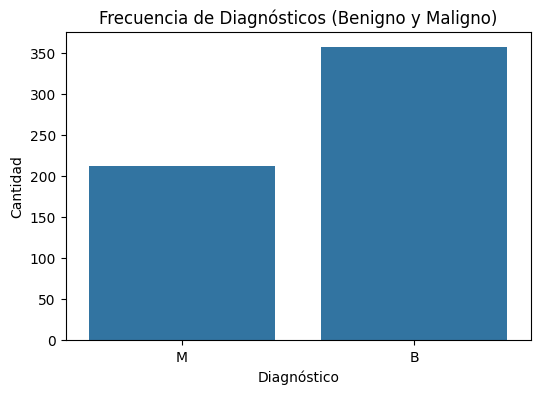

In [ ]:
#utilice sns.countplot()
#-----------------------------------------------------
plt.figure(figsize=(6, 4))
sns.countplot(x='diagnosis', data=data_df)
plt.title('Frecuencia de Diagnósticos (Benigno y Maligno)')
plt.xlabel('Diagnóstico')
plt.ylabel('Cantidad')
plt.show()
#-----------------------------------------------------

2. Como hay tres valores relacionados con la misma característica (`mean`, `se` y `worst`) es muy probable que exista multicolinealidad en el conjunto.

La multicolinealidad en regresión es una condición que ocurre cuando algunas variables predictoras están fuertemente correlacionadas entre sí, de tal manera que si se incluyen simultáneamente en un modelo, impiden explicar de manera correcta el efecto que cada una tiene sobre la variable respuesta. Existen muchas formas de analizar si hay colinealidad en los modelos, una de ellas es el alto coeficiente de correlación entre variables.

Para observar este efecto, elabora un mapa de calor que cuantifique la correlación de las variables numéricas en el dataframe.

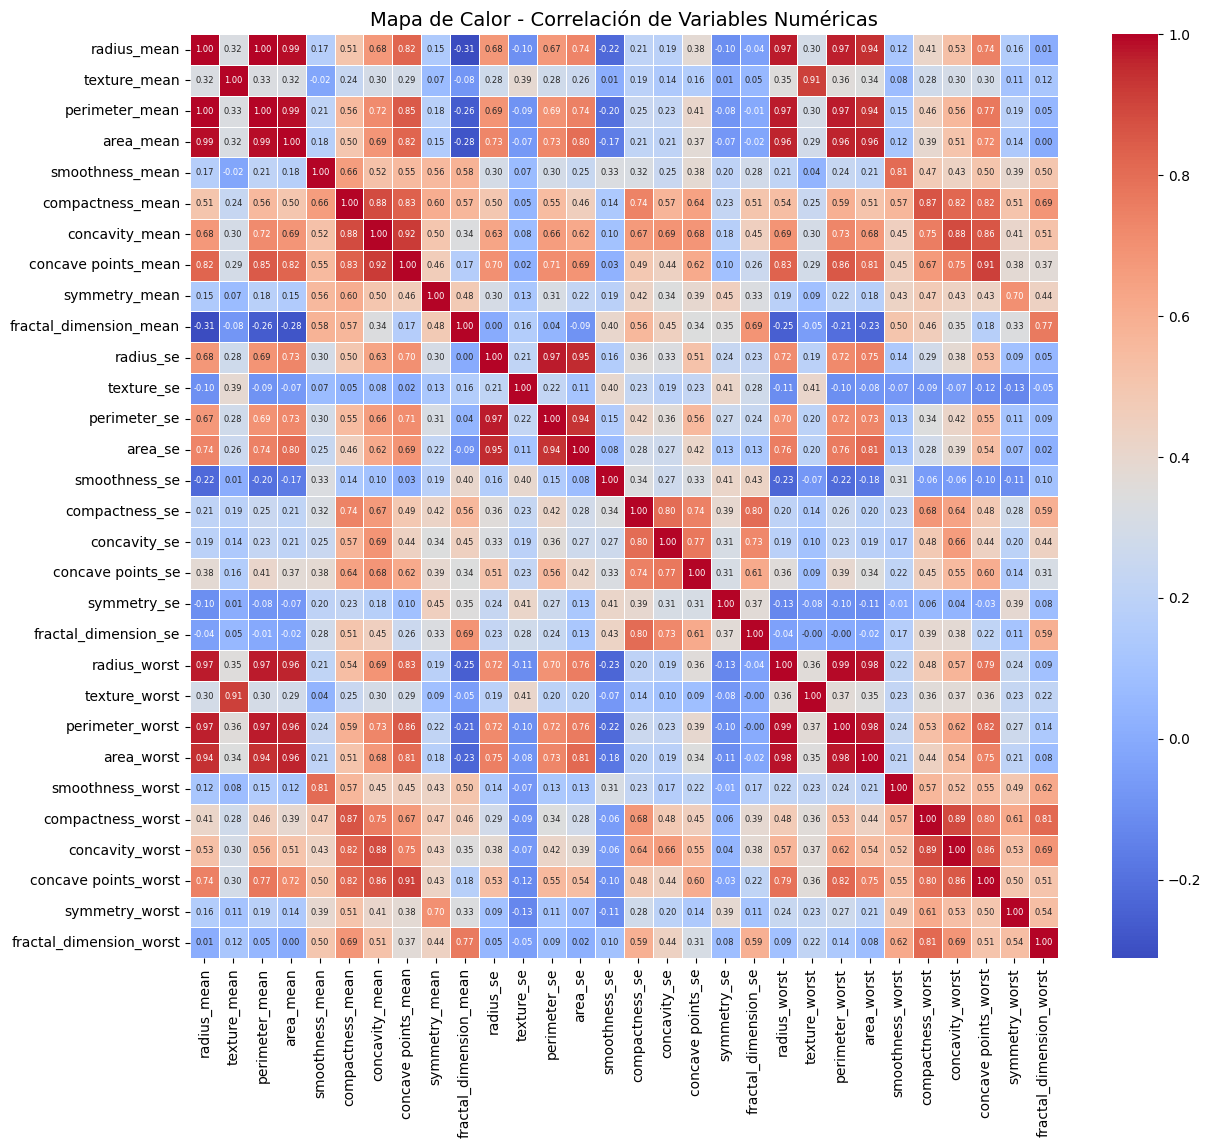

In [ ]:
numeric_df = data_df.select_dtypes(include=[float, int])

#-----------------------------------------------------
plt.figure(figsize=(14, 12))
sns.heatmap(numeric_df.corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, annot_kws={"size": 6})
plt.title('Mapa de Calor - Correlación de Variables Numéricas', fontsize=14)
plt.show()
#-----------------------------------------------------

Si te fijas en los valores de correlación entre las variables `_mean` y `_worst` es evidente la multicolinearidad.

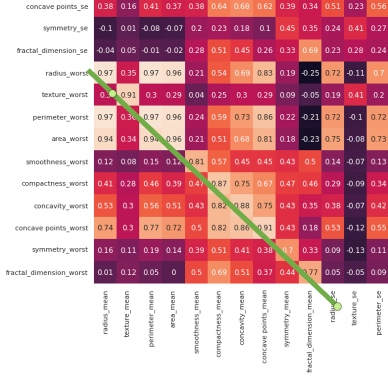

Por ejemplo, la columna `radius_mean` tiene una correlación de 0.97 con la columna `radius_worst`. Esto es algo inevitable, porque las columnas "peores" son esencialmente solo un subconjunto de las columnas "medias".

Para solucionar el problema numérico de la multicolinealidad, tradicionalmente se recurre a eliminar variables o efectuar análisis de componentes principales (PCA) con las `X`’s y usar los componentes como variables independientes en un modelo final.

Conduciremos esta actividad en esos dos sentidos.


# **Parte 2**. Modelo con eliminación de variables altamente correlacionadas  

Elimina las variables altamente correlacionadas:

3a) Ahora que sabes que las variables `_mean` y `_worst` tienen correlación alta, hay que quitar del dataframe un conjunto. Borra las columnas `_worst`.

In [ ]:
#-----------------------------------------------------
#Elimine TODAS las columnas _worst
cols_to_drop = [col for col in data_df.columns if col.endswith('_worst')]
new_data_df = data_df.drop(columns=cols_to_drop)
#-----------------------------------------------------

#para borrar las columnas _worst


#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df)
#-----------------------------------------------------

En las graficas de dispersion, los patrones lineales en los diagramas de dispersion se refieren a la relacion entre dos variables que sigue una tendencia aproximadamente en linea recta, ya sea en direccion ascendente o descentende

* **Patron lineal positivo**: Si la linea se inclina hacia arriba (de izquierda a derecha), indica que hay una relacion directa entre las variables: cuando la variable aumenta, la otra tambien lo hace, es decir, CORRELACION POSITIVA

* **Patron lineal negativo**: si la linea se incluna hacia abajo (de izquierda a derecha), indica quue cuando una variable aumenta, la otra disminuye, es decir, CORRELACION NEGATIVA

* **Patron lineal perfecto**, si los puntos siguen una linea recta perfecta, la relacion entre las variables es exactamente lineal, sin desviaciones.


3b. Entre las variables `_mean`, identifica patrones lineales con diagramas de dispersión usando:

    sns.pairplot(data=nuevo_df[['radius_mean',
        'texture_mean',
        'perimeter_mean',
        'area_mean',
        'smoothness_mean',
        'compactness_mean',
        'concavity_mean',
        'concave points_mean',
        'symmetry_mean',
        'fractal_dimension_mean']])



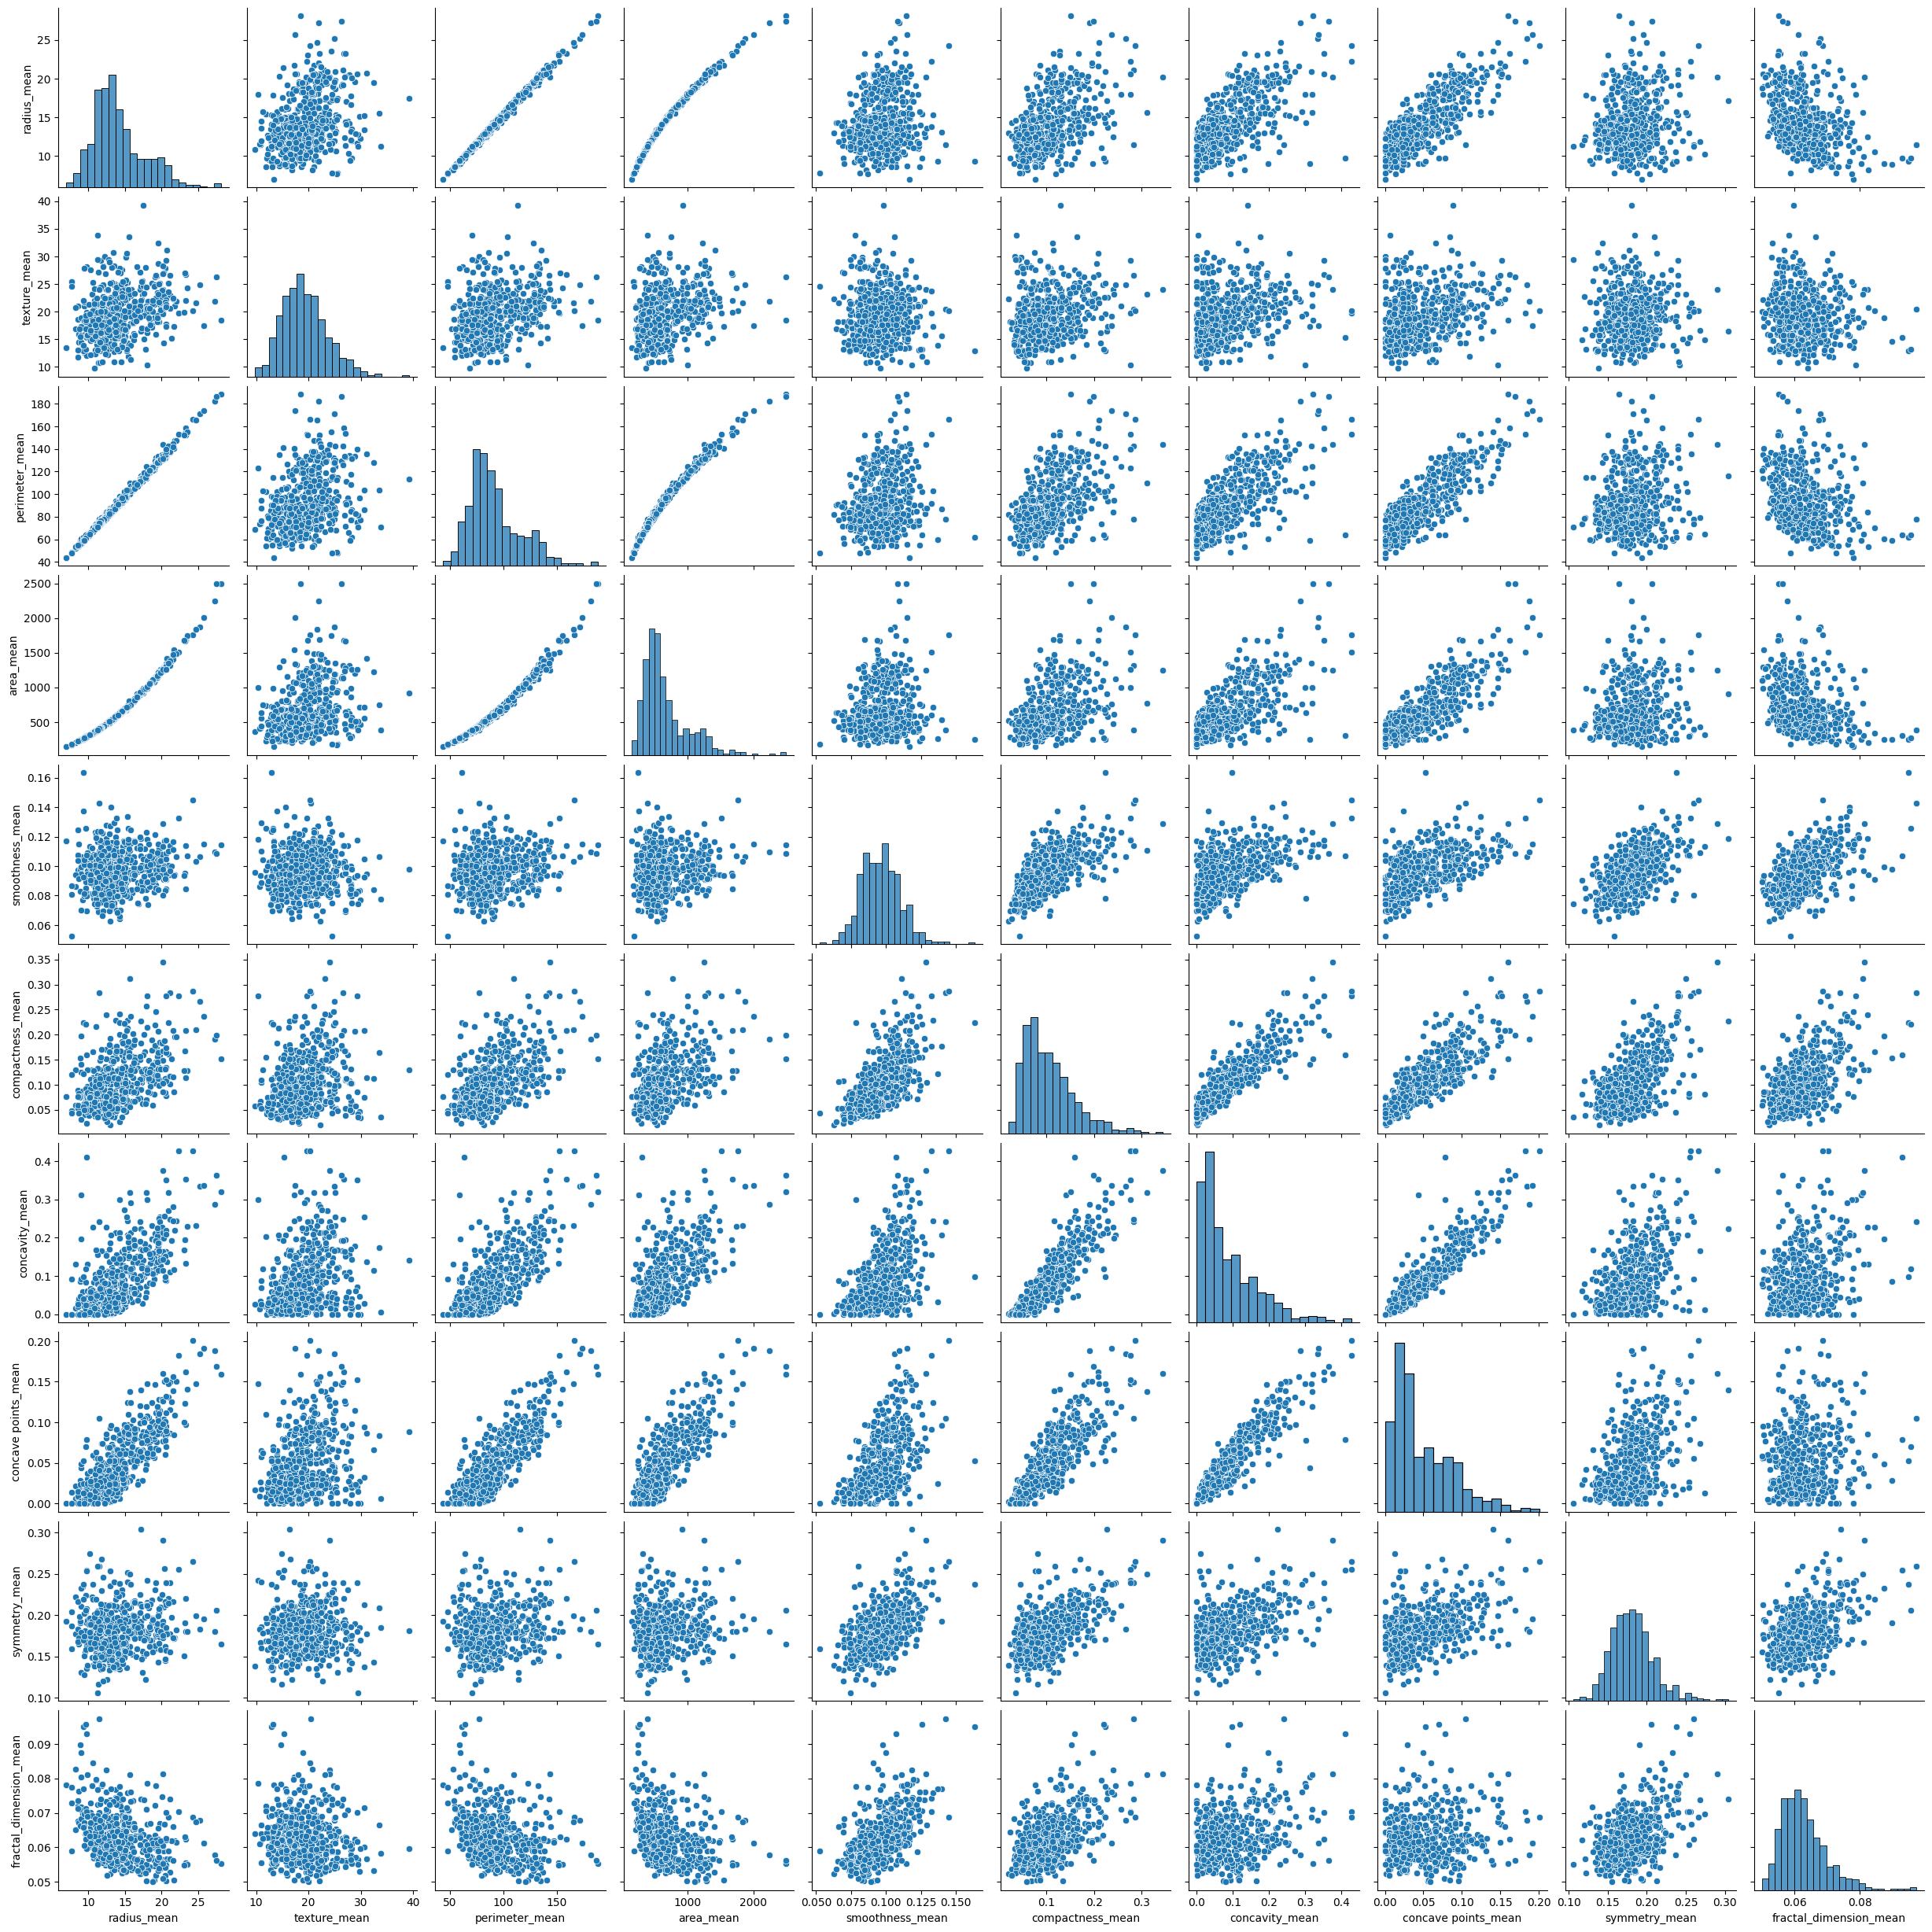

In [ ]:
#-----------------------------------------------------
#Pega aqui el codigo sns.pairplot()
sns.pairplot(data=new_data_df[['radius_mean',
                               'texture_mean',
                               'perimeter_mean',
                               'area_mean',
                               'smoothness_mean',
                               'compactness_mean',
                               'concavity_mean',
                               'concave points_mean',
                               'symmetry_mean',
                               'fractal_dimension_mean']])
plt.show()
#-----------------------------------------------------

De la matriz podrás observar relaciones lineales bastante evidentes entre:


*   `radius_mean`, `perimeter_mean` y `area_mean`
*   `compactness_mean`, `concavity_mean`, `concave_points_mean`

Sabemos que el perímetro y el área de un círculo, se calculan a partir del radio. Entonces, la relación entre las primeras tres variables es muy clara para nosotros.

3c) Elabora otro mapa de calor confirmar con los valores de correlación.


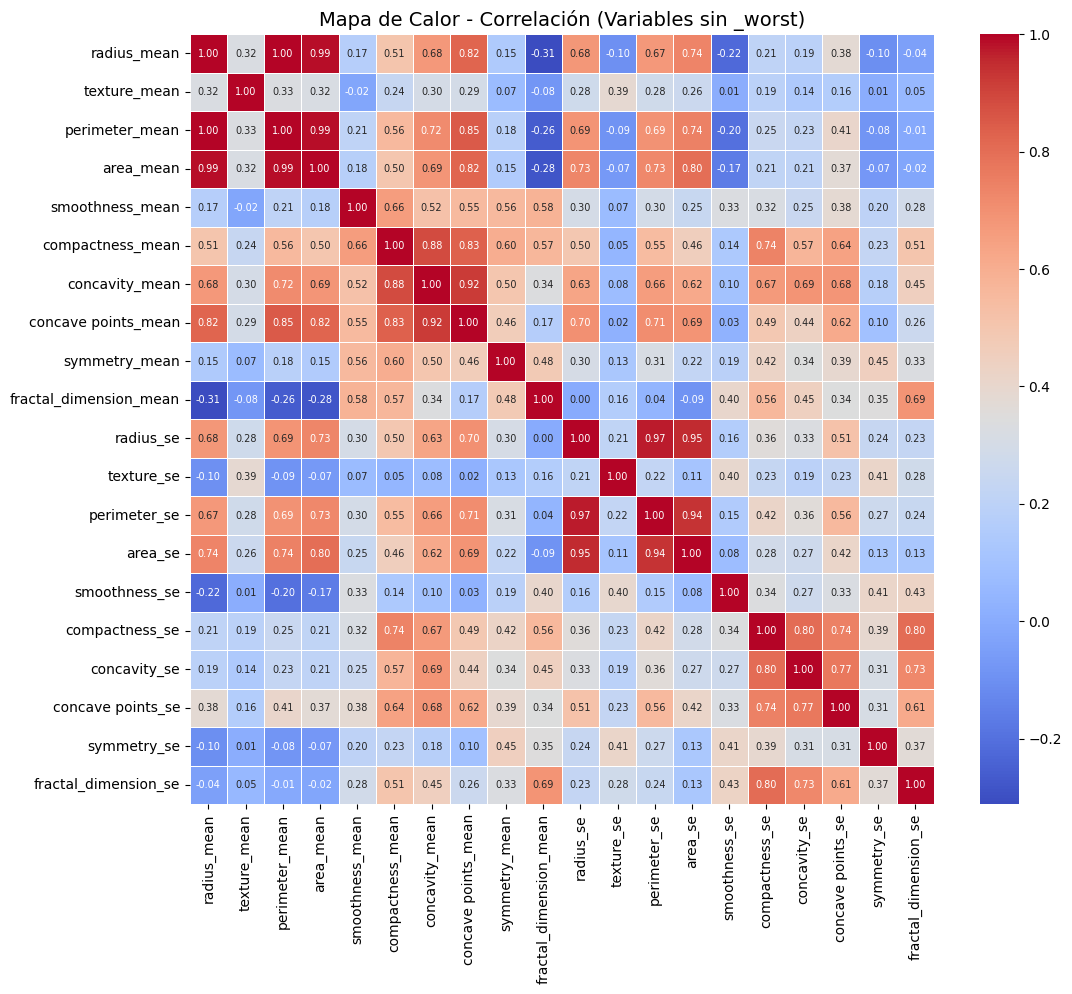

In [ ]:
#-----------------------------------------------------
#Agrega codigo para el mapa de calor
plt.figure(figsize=(12, 10))
sns.heatmap(new_data_df.select_dtypes(include=[float, int]).corr(), annot=True, fmt=".2f", cmap='coolwarm', linewidths=0.5, annot_kws={"size": 7})
plt.title('Mapa de Calor - Correlación (Variables sin _worst)', fontsize=14)
plt.show()
#-----------------------------------------------------

3d) Después de observar los valores, nos quedaremos con sólo una variable de cada trío: `radius_mean` y `compactness_mean`. Elimina las restantes, no sólo del conjunto `_mean`, sino también de `_se`.

In [ ]:

#-----------------------------------------------------
#escriba TODAS las columnas que seran eliminadas
columnas_a_eliminar = [
    'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean',
    'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean',
    'texture_se', 'perimeter_se', 'area_se', 'smoothness_se',
    'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se'
]
#-----------------------------------------------------



#-----------------------------------------------------
#Convierte new_data_df en Dataframe usando .DataFrame() de la libreria de pandas
new_data_df = pd.DataFrame(new_data_df.drop(columns=columnas_a_eliminar))
new_data_df
#-----------------------------------------------------


,diagnosis,radius_mean,compactness_mean,radius_se,compactness_se
id,,,,,
842302,M,17.99,0.27760,1.0950,0.04904
842517,M,20.57,0.07864,0.5435,0.01308
84300903,M,19.69,0.15990,0.7456,0.04006
84348301,M,11.42,0.28390,0.4956,0.07458
84358402,M,20.29,0.13280,0.7572,0.02461
...,...,...,...,...,...
926424,M,21.56,0.11590,1.1760,0.02891
926682,M,20.13,0.10340,0.7655,0.02423
926954,M,16.60,0.10230,0.4564,0.03731


Observa la distribución de las variables resultantes (deben ser 12, sin contar la columna de indice):

4a) Utilizando histogramas. Guarda en una variable (`skew_cols`) las que tengan marcado sesgo positivo. Para dar seguridad a tu selección, elige aquellas cuyo resultado de aplicar la función `skew()` sea mayor a 1.

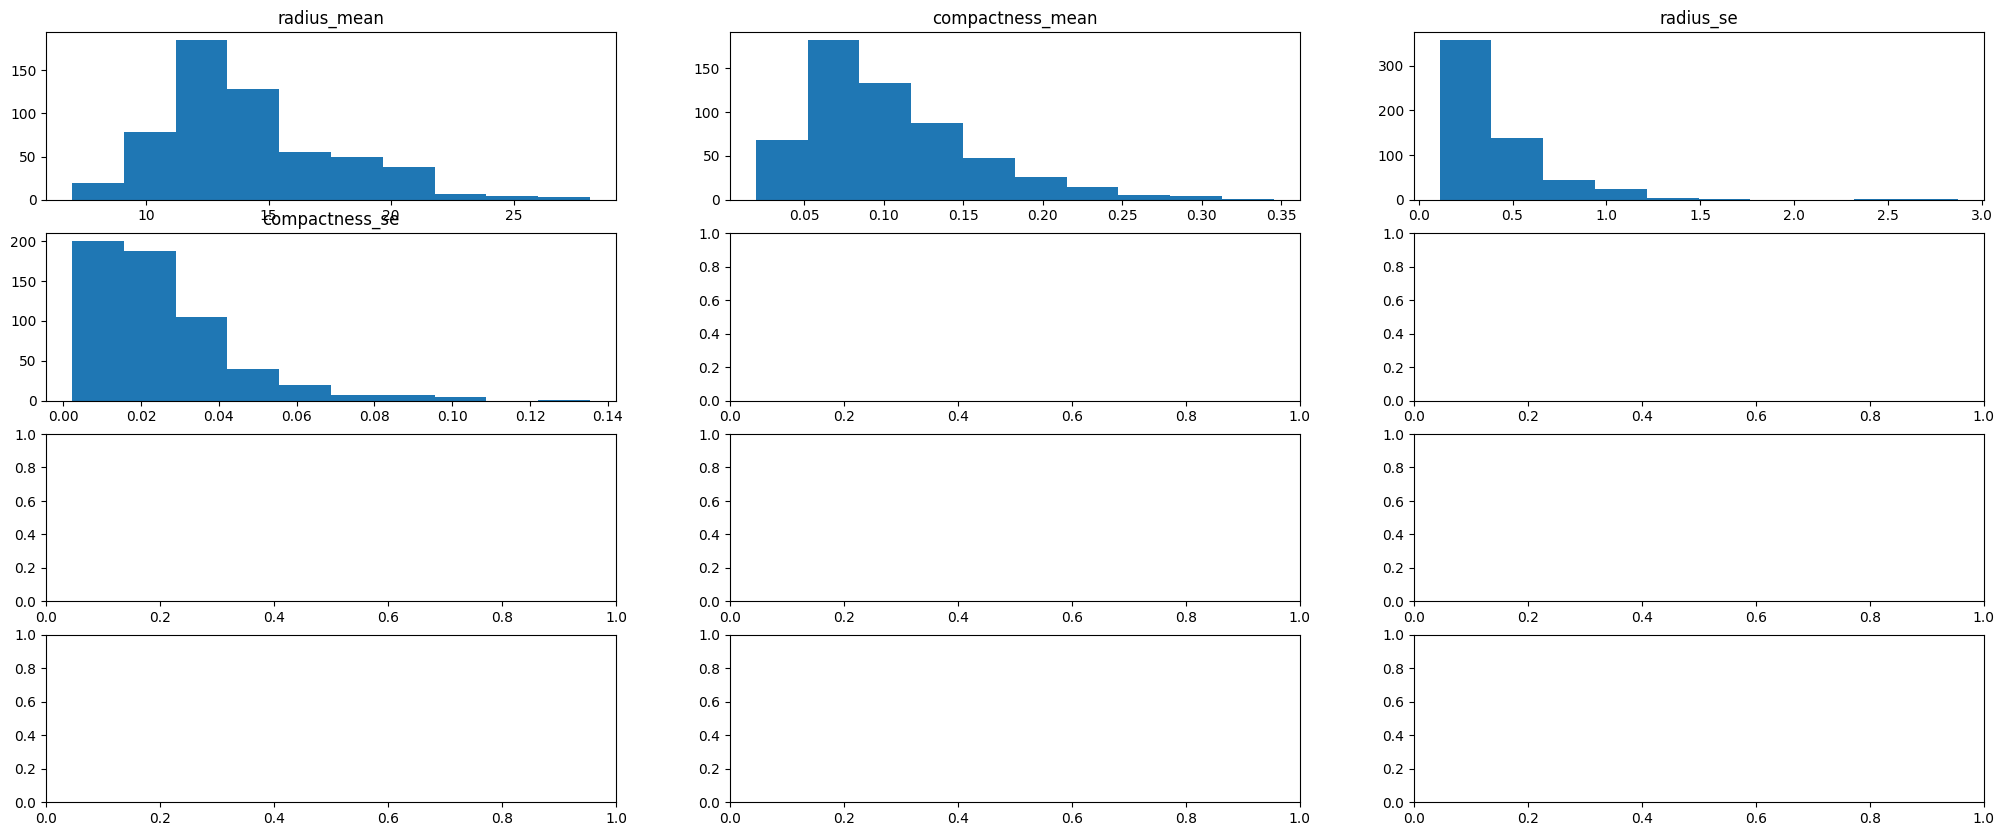

In [ ]:
#EXPLICA CADA LINEA DE CODIGO
skew_cols_df=pd.DataFrame() #Crea un DataFrame vacio que sirve como contenedpr temporal para guardar que columnas cumplen con la condicion de sesgo.
fig, axes =plt.subplots(4,3, figsize=(25,10)) #25 es el ancho, 10 altura   ---- 4,3 significa que seran  4 filas y 3 columnas.
axes = axes.ravel() #Aplaana la matriz de graficos bidimensional en una lista de una sola dimension, lo que permite recorrer cada subgrafico de forma secuencial con un bucle.
num_cols = new_data_df.select_dtypes(include=np.number).columns.tolist() #Filtra y extrae los nombres de todas las columnas de tipo numerido del DataFrame limpio, guardandolos en una lista.


for col, ax in zip (num_cols, axes): #Recorre simultáneamente cada columna junto con su espacio gráfico correspondiente.
  ax.hist(new_data_df[col]) #Dibuja el histograma de la variable actual.
  ax.set(title = f'{col}', xlabel=None) #Asigna el nombre de la variable como título del gráfico y limpia la etiqueta inferior.
  if new_data_df[col].skew()>1 : skew_cols_df[col] =new_data_df[col] #Evalúa el sesgo estadístico; si es mayor a 1, guarda la columna en el DataFrame temporal.

skew_cols = skew_cols_df.columns.values #Extrae los nombres finales de las columnas seleccionadas en un arreglo.



In [ ]:
skew_cols

array(['compactness_mean', 'radius_se', 'compactness_se'], dtype=object)

4b) Dibujando box plots de todas las variables. Guarda en una variable (`scale_cols`) aquellas que no se encuentren en el intervalo [0,1]


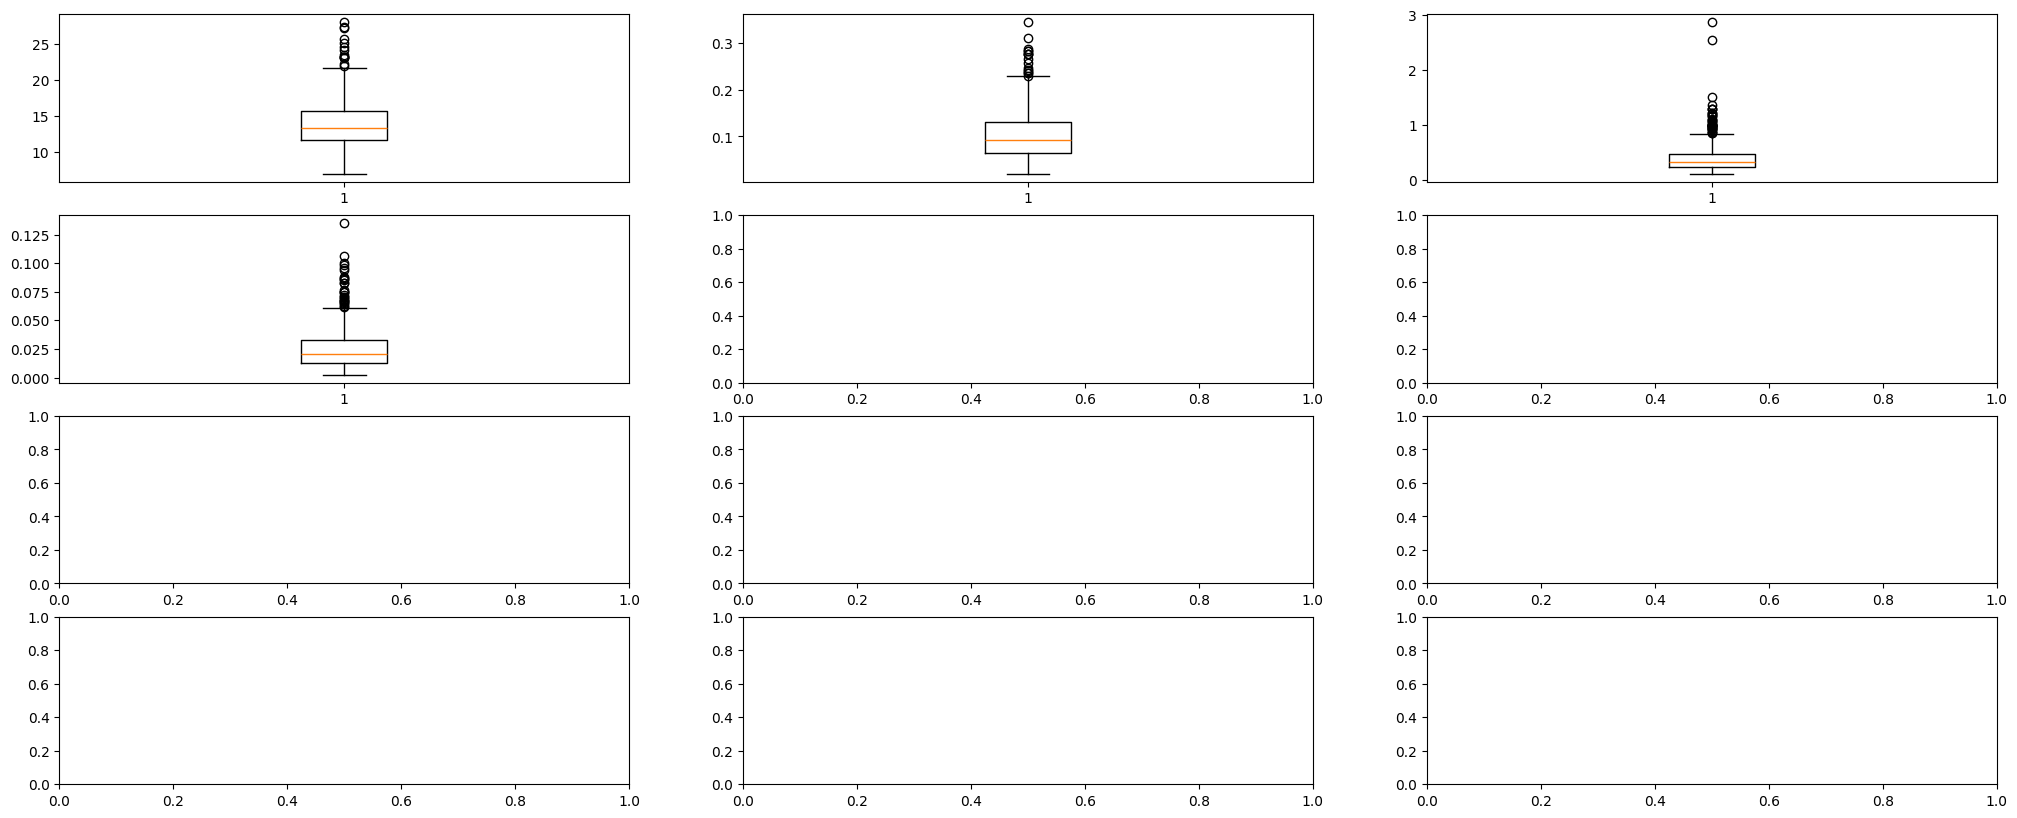

In [ ]:
scale_cols_df=pd.DataFrame()
fig, axes = plt.subplots(4,3, figsize=(25,10))
axes = axes.ravel()

#-----------------------------------------------------
for col, ax in zip(new_data_df[num_cols], axes):
    ax.boxplot(new_data_df[col])  # COMPLETA LINEA DE CODIGO

    # COMPLETA EL IF
    if new_data_df[col].min() < 0 or new_data_df[col].max() > 1:
        scale_cols_df[col] = new_data_df[col]
#-----------------------------------------------------

scale_cols = scale_cols_df.columns.values



In [ ]:
scale_cols

array(['radius_mean', 'radius_se'], dtype=object)

Con todo el análisis anterior, estamos listos para generar un modelo *baseline* denominado `logr_model`. Para ello:

5a) Vuelve a leer el contenido del archivo, haz que el `id` sea el índice y separa las variables del dataframe: en `X` coloca los predictores y en `y` la variable de respuesta o salida (`diagnosis`). Divide el conjunto en entrenamiento y prueba (80:20) considerando el parámetro `random_state` con el valor de 1.

In [ ]:
data_df = pd.read_csv('data.csv')

#-----------------------------------------------------
#AGREGA LINEA DE CODIGO PARA CONVERTIR COLUMNA "ID" EN INDICE
data_df.set_index('id', inplace=True)
#-----------------------------------------------------

In [ ]:
X = data_df.copy() #Se crea copia del df


#-----------------------------------------------------
#                                  COMPLETA CODIGO
# se elimina variable Categorica "diagnosis" de (X), debido a se sera utilizada como variable de salida (y)
#-----------------------------------------------------
#Especifique la columna que desea eliminar
#Utilice el parametro axis=1, permitira eliminar la columna
#Guarde los cambios agregando el parametro inplace=True

X.drop('diagnosis', axis=1, inplace=True) #Caracteristica / variable Entrada
#-----------------------------------------------------

#-----------------------------------------------------
y = data_df['diagnosis'] #Objetivo /Variable salida
#-----------------------------------------------------

In [ ]:
#Libreria necesaria para realizar la particion del conjunto de datos
from sklearn.model_selection import train_test_split

# Se divide el conjunto en entrenamiento y prueba (80:20), es decir, 80% para Entrenamiento (train) y 20% para Prueba (test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

5b) Prepara un transformador, denominado `preprocessing`, para borrar las columnas altamente correlacionadas (las 18 variables que se determinaron en los ejercicios previos) Asegúrate de incluir el parámetro `remainder='passthrough'` para mantener el resto de las variables.

In [ ]:
#EXPLIQUE CADA LINEA DE CODIGO
columnas_a_eliminar=['radius_worst','texture_worst','perimeter_worst','area_worst','smoothness_worst','compactness_worst','concavity_worst','concave points_worst','symmetry_worst','fractal_dimension_worst','perimeter_mean','area_mean','concavity_mean','concave points_mean','perimeter_se','area_se','concavity_se','concave points_se']

preprocessing = ColumnTransformer([
    ('num', 'drop', columnas_a_eliminar)]
   ,remainder='passthrough')


5c) Entrena el modelo `logr_model` con el transformador `preprocessing` y  regresión logística.

Como la salida `y` está en términos de las etiquetas `'B'` y `'M'`, en lugar de 0 y 1, para evaluar el modelo en el conjunto de prueba deberás especificar la clase positiva. En el caso de la matriz de confusión, indica el orden de las etiquetas con `labels=['B','M']`, porque `'B'` es la clase negativa (ésta se especifica primero) y `'M'` la positiva. Para las métricas de *recall* y *precision*, utiliza el parámetro `pos_label='M'`. Como *accuracy* ocupa la suma de ambas clases y el total de las observaciones, no requiere ninguna especificación. Si quisieras omitir estos parámetros, tendrías que sustituir `'B'` por 0 y `'M'` por 1, previo a la construcción del modelo.

In [ ]:
# EXPLIQUE CADA LINEA DE CODIGO

logr_model = make_pipeline(preprocessing, LogisticRegression()) # Crea un pipeline que combina el preprocesamiento de los datos y el modelo de Regresión Logística, asignándolo a la variable logr_model.
logr_model.fit(X_train, y_train) # Entrena el modelo utilizando los datos de entrenamiento (características X_train y etiquetas y_train).
predictions = logr_model.predict(X_test) # Genera las predicciones de la etiqueta de salida utilizando el conjunto de prueba (X_test).

print('matriz de confusion 1:\n', confusion_matrix(y_test, predictions, labels=['B', 'M'])) # Imprime la matriz de confusión comparando los valores reales (y_test) con las predicciones, ordenando las etiquetas con 'B' (negativa) y 'M' (positiva).
print('recall    :\t', recall_score(y_test, predictions, pos_label='M')) # Calcula e imprime la métrica de sensibilidad (recall) especificando a 'M' como la clase positiva de interés.
print('precision :\t', precision_score(y_test, predictions, pos_label='M')) # Calcula e imprime la métrica de precisión indicando a 'M' como la clase positiva.
print('accurancy :\t', accuracy_score(y_test, predictions)) # Calcula e imprime la exactitud (accuracy) general comparando el total de aciertos del modelo.



matriz de confusion 1:
 [[68  4]
 [10 32]]
recall    :	 0.7619047619047619
precision :	 0.8888888888888888
accurancy :	 0.8771929824561403


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

Para generar un modelo `logr_model2` con transformación y escalamiento:

6a) Modifica el transformador anterior para, además del borrado de las columnas correlacionadas, aplicar la raíz cuadrada a los predictores con sesgo (previamente almacenados en `skew_cols`) y escalamiento *MinMax* a los predictores con escala mayor a 1 (previamente almacenados en `scale_cols`) Como no todos los predictores serán eliminados o transformados, asegúrate de incluir el parámetro `remainder='passthrough'`

In [ ]:
#EXPLIQUE CADA LINEA DE CODIGO
preprocessing2 = ColumnTransformer([ # Inicializa un tranformador para aplicar diferentes operaciones a columnas especificas en paralelo.
    ('num0','drop', columnas_a_eliminar), # Elimina todas las columnas redundantes o altamente correlacionadas.
    ('num1',FunctionTransformer(np.sqrt),skew_cols), # Aplica la raíz cuadrada para corregir el sesgo positivo en las variables seleccionadas.
    ('num2',MinMaxScaler(),scale_cols) # Aplica un reescalado MinMax a las variables cuyos valores superan el rango de 0 a 1.
  ],remainder='passthrough') # Deja intactas y permite el paso de cualquier otra columna numérica no mencionada.

6b) Entrena el modelo `logr_model2` con regresión logística, aplicando previamente el transformador modificado. Evalúa el modelo en el conjunto de prueba con las mismas métricas.

In [ ]:
#ESCRIBA CODIGO AQUI
logr_model2 = make_pipeline(preprocessing2, LogisticRegression())
logr_model2.fit(X_train, y_train)
predictions2 = logr_model2.predict(X_test)

print('matriz de confusion 2:\n', confusion_matrix(y_test, predictions2, labels=['B', 'M']))
print('recall    :\t', recall_score(y_test, predictions2, pos_label='M'))
print('precision :\t', precision_score(y_test, predictions2, pos_label='M'))
print('accurancy :\t', accuracy_score(y_test, predictions2))


matriz de confusion 2:
 [[69  3]
 [ 9 33]]
recall    :	 0.7857142857142857
precision :	 0.9166666666666666
accurancy :	 0.8947368421052632


<font color=" ORANGE">INTERPRETE LOS RESULTADOS OBTENIDOS EN MATRIZ DE CONFUSION Y METRICAS

El modelo "logr_model2" alcanzo una exactitud global (accuracy) del 89.47%, consiguiendo identificar correctamente 69 casos benignos y 3 malignos segun la matriz de confusion. En cuando el desempeño, presenta una alta presicion de 91.67%, lo que nos dice que al momento de que el modelo predice una  "anomalia" es sumamente confiable y genera muy pocas falsas alarmas mas que en solo 3 casos. No obstante, el recall del 78.57% nos dice que 9 casos malignos (falsos negativos) reales no fueron detectados, un margen de error puede requerir ajustes posteriores en el umbral de clasificacion para priorizar la deteccion de una enfermedad.

<font color=" ORANGE">CONCLUSION DE LA PRACTICA

Esta practica demuestra que una correcta preparacion y analisis exploratorio de los datos son fundamentales para que los modelos de Machine Learning tengan exito, especialmente en entornos de diagnostico medicos donde la precision es critica. A traves de la depuracion de la multicolinealidad, la correccion de sesgos y escalamiento adecuado de las variables, se pudo contruir un flujo de trabajo optimizzado que mejora la calidad de la informacion ingresada a la Regresion Logistia. Los resultados subrayan que la evaluacion de un modelo va mas alla de la exactitud global, requiriendo un analisis detallado de metricas como el recall y la precision para equilibrar la confianza en las predicciones con la minimizacion de riesgos.